# Video Game Sales Prediction on Steam Data
## Notebook 8 — Modification 5: Forecasting Later Releases

**Motivation.** Notebook 7 found that the reference model scores R² (log) 0.460 with random folds but only
0.165 when it is trained on releases up to 2021 and scored on releases from 2022 to June 2024. It attributed
the drop mainly to release year: owners are counted in 2025, so older games have had longer to sell, and a
model cannot learn that effect for years it has never seen. The planned fix was a target measured relative to
games of the same release year.

**Purpose.** This notebook first measures where the drop comes from, then tests that fix and three related
changes, one at a time, on the reference model of Notebook 7 (Gradient Boosting on log1p(owners), 49
variables):

| Experiment | Change | Idea |
|---|---|---|
| E11 | Release year removed from the variables | Diagnostic: how much does the model depend on it? |
| E12 | Year-relative target | Predict log owners minus the mean of the same release year |
| E13 | Trained on 2017–2021 releases only | Recent games may resemble future games more than old ones do |
| E14 | Year level from a trend | With E12, extend the falling year level by a straight line instead of holding it flat |

**Rules.**
- **Split:** as in Notebook 7 (Section 12.5), training-set games released up to 2021 are used for fitting and
  those released from 2022 to June 2024 for scoring. The test set is not used in this notebook.
- **Adoption:** a change is adopted only if it raises the chronological R² (log) by at least 0.01, averaged
  over five random seeds, and the gain also holds when each year is predicted from the years before it
  (Section 13.4).

**Questions.**
1. How much of the drop from 0.460 to 0.165 is caused by the release-year level?
2. Does a year-relative target, or any of the other changes, improve forecasts for later releases?
3. What accuracy can honestly be claimed for a game that has not been released yet?

The same experiments are recorded as E11–E14 in `experiments/EXPERIMENT_LOG.md`.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, train_test_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42
SEEDS = [42, 1, 2, 3, 4]

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
with open(os.path.join(DATA_DIR, "engineered_features.json")) as f:
    groups = json.load(f)
engineered = pd.read_csv(os.path.join(DATA_DIR, "engineered_features.csv.gz"))   # written by Notebook 7
data = data.merge(engineered, on="appid", how="left", validate="one_to_one")     # keeps the row order of Notebook 1

ADOPTED = spec["numeric"] + spec["genres"] + spec["categories"] \
    + groups["A. Studio experience"] + groups["C. Store-page lead time"]
NO_YEAR = [c for c in ADOPTED if c != "release_year"]
data["owners"] = (data["owners_millions"] * 1e6).round()
data["log_owners"] = np.log1p(data["owners"])

train, _ = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)   # the test set is not used in this notebook
train = train.reset_index(drop=True)
CUTOFF = pd.Timestamp("2021-12-31")
early, late = train[train["release_dt"] <= CUTOFF], train[train["release_dt"] > CUTOFF]
print(f"Training set: {len(train):,} games, {len(ADOPTED)} variables (reference model of Notebook 7)")
print(f"Released up to 2021: {len(early):,} | released 2022 to June 2024: {len(late):,}")

Training set: 61,381 games, 49 variables (reference model of Notebook 7)
Released up to 2021: 38,450 | released 2022 to June 2024: 22,931


---
# 13. Modification 5: Forecasting Later Releases

## 13.1 How owners change with release year

Table 37 describes the target by release year. All owner counts are the 2025 snapshot.

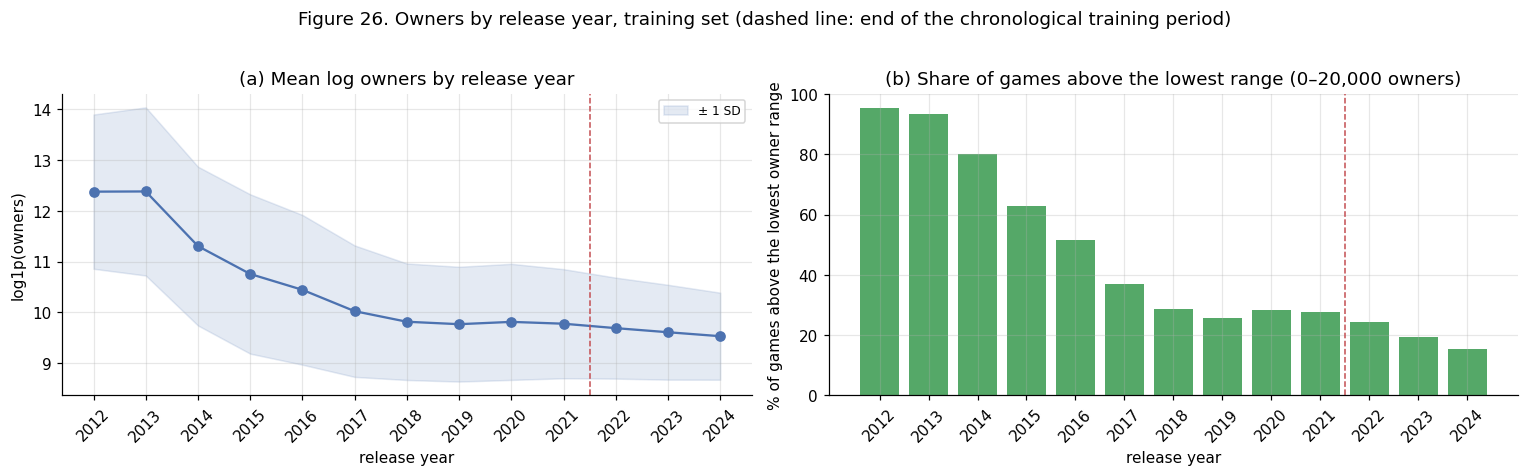

,Games,Mean log owners,SD of log owners,Median owners,Share above the lowest owner range
Release year,,,,,
2012,260,12.38,1.52,"350,000",95.4%
2013,355,12.38,1.66,"350,000",93.5%
2014,"1,174",11.31,1.56,"75,000",80.2%
2015,"1,959",10.76,1.57,"35,000",62.8%
2016,"3,231",10.44,1.48,"35,000",51.7%
2017,"4,608",10.02,1.30,"10,000",36.9%
2018,"5,755",9.82,1.15,"10,000",28.6%
2019,"5,743",9.77,1.13,"10,000",25.7%
2020,"6,875",9.81,1.14,"10,000",28.2%


In [2]:
by_year = train[train["release_year"] >= 2012].groupby("release_year")
table37 = pd.DataFrame({
    "Games": by_year.size(),
    "Mean log owners": by_year["log_owners"].mean(),
    "SD of log owners": by_year["log_owners"].std(),
    "Median owners": by_year["owners"].median(),
    "Share above the lowest owner range": by_year["owners"].apply(lambda s: (s > 10_000).mean()),
})
table37.index.name = "Release year"
table37.to_csv(os.path.join(TAB_DIR, "table37_owners_by_release_year.csv"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
years = table37.index
axes[0].plot(years, table37["Mean log owners"], "o-", color=BLUE)
axes[0].fill_between(years, table37["Mean log owners"] - table37["SD of log owners"],
                     table37["Mean log owners"] + table37["SD of log owners"], color=BLUE, alpha=0.15, label="± 1 SD")
axes[0].set_ylabel("log1p(owners)")
axes[0].set_title("(a) Mean log owners by release year")
axes[0].legend(fontsize=8)
axes[1].bar(years, 100 * table37["Share above the lowest owner range"], color=GREEN)
axes[1].set_ylabel("% of games above the lowest owner range")
axes[1].set_title("(b) Share of games above the lowest range (0–20,000 owners)")
for ax in axes:
    ax.axvline(2021.5, color=RED, ls="--", lw=1)
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("release year")
fig.suptitle("Figure 26. Owners by release year, training set (dashed line: end of the chronological training period)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig26_owners_by_release_year.png"), dpi=150, bbox_inches="tight")
plt.show()
table37.style.format({"Games": "{:,}", "Mean log owners": "{:.2f}", "SD of log owners": "{:.2f}",
                      "Median owners": "{:,.0f}", "Share above the lowest owner range": "{:.1%}"}).set_caption(
    "Table 37. Owners by release year (training set; owners as counted in 2025)")

**Interpretation.**
- **The level falls with release year.** Mean log owners falls from 12.38 for 2012 releases to 9.53 for 2024
  releases. The fall is steep until 2018 and slow afterwards.
- **The spread narrows too.** The SD of log owners falls from 1.52 to 0.86. In 2012, 95.4% of games were above
  the lowest owner range; among 2022, 2023 and 2024 releases only 24.3%, 19.5% and 15.5% are. From 2017 onward
  the median game sits in the lowest range.
- **Two separate consequences follow.** A model must get the level of a year right, and for recent years there
  is less difference between games left to explain, because most of them share one owner range.

## 13.2 Where the drop comes from

Two measures separate the level of a year from the ranking of games within it:
- **Within-year R² (log):** R² after the release-year mean is removed from both actual and predicted values.
  It ignores any error in the level of a year.
- **Bias (log):** mean prediction minus mean actual. Above zero means over-prediction.

Table 38 scores the same reference model three ways.

In [3]:
def within_year_r2(y, pred, year):
    """R² after the release-year mean is removed from both the actual and the predicted values. It measures
    how well games are told apart within one release year and ignores any error in the level of a year."""
    y, pred = pd.Series(np.asarray(y)), pd.Series(np.asarray(pred))
    year = np.asarray(year)
    return r2_score(y - y.groupby(year).transform("mean"), pred - pred.groupby(year).transform("mean"))


def evaluate(frame, pred):
    y = frame["log_owners"].to_numpy()
    return {"R² (log)": r2_score(y, pred), "Within-year R² (log)": within_year_r2(y, pred, frame["release_year"]),
            "Bias (log)": float(np.mean(pred - y))}


def forecast(features, fit_frame, score_frame, relative=False, level="last", seed=RANDOM_STATE):
    """Gradient Boosting (defaults) fitted on `fit_frame`, predictions of log1p(owners) for `score_frame`.
    relative=True: the target is log owners minus the mean log owners of the game's release year, computed
    on `fit_frame` only. The year level is then added back:
      level="own"   the mean of the game's own release year (possible only when that year is in `fit_frame`);
      level="last"  the mean of the last year in `fit_frame`;
      level="trend" a straight line through the means of the last five years in `fit_frame`."""
    model = HistGradientBoostingRegressor(random_state=seed)
    y_fit = fit_frame["log_owners"]
    if not relative:
        return model.fit(fit_frame[features], y_fit).predict(score_frame[features])
    year_mean = y_fit.groupby(fit_frame["release_year"]).mean()
    pred = model.fit(fit_frame[features], y_fit - fit_frame["release_year"].map(year_mean)).predict(score_frame[features])
    if level == "own":
        return pred + score_frame["release_year"].map(year_mean).fillna(y_fit.mean()).to_numpy()
    if level == "last":
        return pred + year_mean.iloc[-1]
    slope, intercept = np.polyfit(year_mean.index[-5:], year_mean.iloc[-5:], 1)
    return pred + intercept + slope * score_frame["release_year"].to_numpy()


folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))


def random_folds(features, relative=False):
    """Out-of-fold predictions and mean fold R² with the random folds of Notebooks 5–7."""
    oof, r2 = np.zeros(len(train)), []
    for tr, va in folds:
        oof[va] = forecast(features, train.iloc[tr], train.iloc[va], relative, level="own")
        r2.append(r2_score(train["log_owners"].to_numpy()[va], oof[va]))
    return oof, float(np.mean(r2))

Mean R² (log) of the five random folds: 0.460


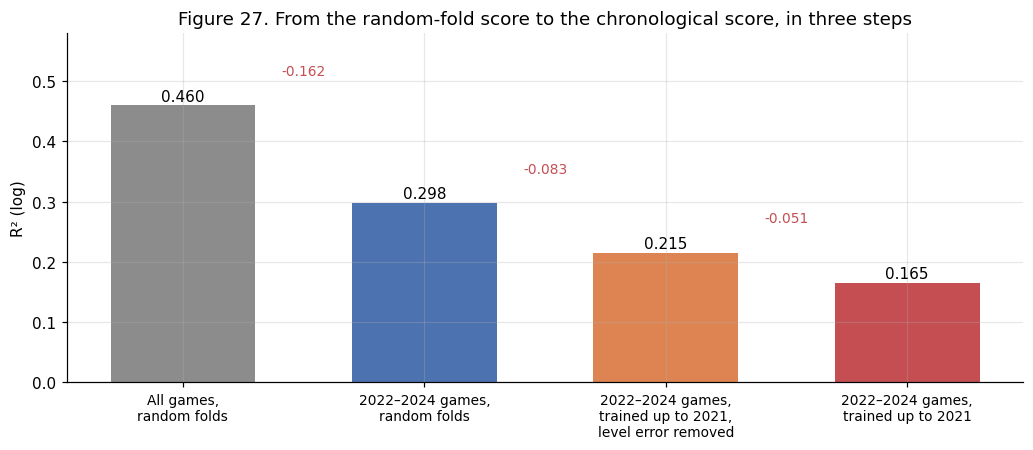

In [4]:
reference_oof, reference_cv = random_folds(ADOPTED)
is_late = (train["release_dt"] > CUTOFF).to_numpy()
chronological = forecast(ADOPTED, early, late)

rows = [
    {"Games scored": "All training games", "Trained on": "Random folds (all years)", **evaluate(train, reference_oof)},
    {"Games scored": "Released 2022–2024", "Trained on": "Random folds (all years)", **evaluate(late, reference_oof[is_late])},
    {"Games scored": "Released 2022–2024", "Trained on": "Releases up to 2021", **evaluate(late, chronological)},
]
table38 = pd.DataFrame(rows).set_index(["Games scored", "Trained on"])
table38.to_csv(os.path.join(TAB_DIR, "table38_chronological_gap.csv"))
print(f"Mean R² (log) of the five random folds: {reference_cv:.3f}")

steps = [("All games,\nrandom folds", table38["R² (log)"].iloc[0], GREY),
         ("2022–2024 games,\nrandom folds", table38["R² (log)"].iloc[1], BLUE),
         ("2022–2024 games,\ntrained up to 2021,\nlevel error removed", table38["Within-year R² (log)"].iloc[2], ORANGE),
         ("2022–2024 games,\ntrained up to 2021", table38["R² (log)"].iloc[2], RED)]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(range(4), [s[1] for s in steps], color=[s[2] for s in steps], width=0.6)
for i, (_, v, _) in enumerate(steps):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=10)
    if i:
        ax.text(i - 0.5, max(v, steps[i - 1][1]) + 0.05, f"{v - steps[i - 1][1]:+.3f}", ha="center", fontsize=9, color=RED)
ax.set_xticks(range(4))
ax.set_xticklabels([s[0] for s in steps], fontsize=9)
ax.set_ylim(0, 0.58)
ax.set_ylabel("R² (log)")
ax.set_title("Figure 27. From the random-fold score to the chronological score, in three steps")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig27_chronological_gap.png"), dpi=150, bbox_inches="tight")
plt.show()
table38.style.format({"R² (log)": "{:.3f}", "Within-year R² (log)": "{:.3f}", "Bias (log)": "{:+.3f}"}).set_caption(
    "Table 38. The reference model scored on all games and on 2022–2024 games (Gradient Boosting, 49 variables)")

**Interpretation.** The drop from 0.460 to 0.165 has three parts (Figure 27).
1. **Scoring only 2022–2024 games, still with random folds: 0.460 → 0.298 (−0.162).** This is the largest
   part, and it has nothing to do with forecasting, because the model still trains on games of the same years.
   The overall score is helped by differences between release years (the within-year R² of all games is
   0.358), and recent games have less variation to explain (Section 13.1).
2. **Training only on older games: 0.298 → 0.215 (−0.083).** With the level error set aside, the model still
   tells 2022–2024 games apart less well when it has seen no game from those years.
3. **The level error: 0.215 → 0.165 (−0.051).** Predictions are too high by 0.20 on the log scale, about 23% in
   owners, because the model treats later games like 2021 games, which have had longer to sell.

**The release-year level is the smallest of the three parts.** Notebook 7 named it as the main cause; this
decomposition corrects that. A fix for the level can recover at most 0.051.

## 13.3 Four changes, one at a time (E11–E14)

Each change is applied to the reference model and scored on the chronological split. Gradient Boosting's
early stopping depends on the random seed, so each model is also fitted with five seeds; the gain is the
difference in the five-seed means. Where it applies, the random-fold score is given for comparison.

For the year-relative target (E12), the mean log owners of each release year is computed on the fitting games
and subtracted from the target. For a later year that mean is unknown, so the mean of the last fitting year
(2021) is added back. E14 extends the means of the last five fitting years by a straight line instead.

In [5]:
THRESHOLD = 0.01
EXPERIMENTS = [
    # id, change, variables, games fitted on, relative target, year level, random-fold reference
    ("E08 (reference)", "49 variables of Notebook 7", ADOPTED, early, False, None, (ADOPTED, False)),
    ("E11", "Release year removed", NO_YEAR, early, False, None, (NO_YEAR, False)),
    ("E12", "Year-relative target", ADOPTED, early, True, "last", (ADOPTED, True)),
    ("E12 + E11", "Year-relative target, release year removed", NO_YEAR, early, True, "last", (NO_YEAR, True)),
    ("E13", "Trained on 2017–2021 releases only", ADOPTED, early[early["release_year"] >= 2017], False, None, None),
    ("E14", "Year-relative target, level from a five-year trend", ADOPTED, early, True, "trend", None),
]
rows = []
for exp_id, change, features, fit_frame, relative, level, reference in EXPERIMENTS:
    scores = evaluate(late, forecast(features, fit_frame, late, relative, level))
    by_seed = [r2_score(late["log_owners"], forecast(features, fit_frame, late, relative, level, seed)) for seed in SEEDS]
    rows.append({"Experiment": exp_id, "Change": change, "Games fitted on": len(fit_frame), **scores,
                 "R² (log), mean of 5 seeds": np.mean(by_seed), "Seed range": f"{min(by_seed):.3f} to {max(by_seed):.3f}",
                 "Random-fold CV R² (log)": random_folds(*reference)[1] if reference else np.nan})
table39 = pd.DataFrame(rows).set_index("Experiment")
table39.insert(table39.columns.get_loc("Seed range"), "Gain",
               table39["R² (log), mean of 5 seeds"] - table39["R² (log), mean of 5 seeds"].iloc[0])
table39.loc["E08 (reference)", "Gain"] = np.nan
table39.to_csv(os.path.join(TAB_DIR, "table39_forecasting_experiments.csv"))
table39.style.format({"Games fitted on": "{:,}", "R² (log)": "{:.3f}", "Within-year R² (log)": "{:.3f}",
                      "Bias (log)": "{:+.3f}", "R² (log), mean of 5 seeds": "{:.3f}", "Gain": "{:+.3f}",
                      "Random-fold CV R² (log)": "{:.3f}"}, na_rep="").set_caption(
    "Table 39. Fitted on releases up to 2021 and scored on 2022–2024 releases (first three score columns: seed 42)")

,Change,Games fitted on,R² (log),Within-year R² (log),Bias (log),"R² (log), mean of 5 seeds",Gain,Seed range,Random-fold CV R² (log)
Experiment,,,,,,,,,
E08 (reference),49 variables of Notebook 7,"38,450",0.165,0.215,+0.203,0.164,,0.158 to 0.171,0.460
E11,Release year removed,"38,450",-0.013,0.132,+0.354,-0.011,-0.175,-0.013 to -0.010,0.357
E12,Year-relative target,"38,450",0.172,0.219,+0.195,0.167,+0.004,0.162 to 0.175,0.457
E12 + E11,"Year-relative target, release year removed","38,450",0.127,0.168,+0.182,0.121,-0.043,0.117 to 0.127,0.429
E13,Trained on 2017–2021 releases only,"30,532",0.180,0.228,+0.199,0.170,+0.006,0.162 to 0.180,
E14,"Year-relative target, level from a five-year trend","38,450",0.215,0.219,+0.064,0.212,+0.049,0.208 to 0.218,


**Interpretation.**
- **Release year cannot simply be removed (E11).** Without it, chronological R² falls to −0.011, the
  over-prediction grows to +0.35 and within-year R² falls from 0.215 to 0.132. The random-fold score falls from
  0.460 to 0.357. Release year therefore helps the model tell games apart within a year as well, which means
  the link between store-page variables and sales has changed over time.
- **The year-relative target changes almost nothing (E12).** R² is 0.167 against 0.164 (+0.004) and within-year
  R² 0.219 against 0.215. Gradient Boosting with release year as a variable already learns the level of each
  year, so removing the level from the target gives it nothing new. Combined with E11 it is worse (0.121).
- **Training on recent years only does not help (E13).** The gain is +0.006, and the seed ranges of the two
  models overlap (0.162–0.180 against 0.158–0.171).
- **A trend for the year level helps on this split (E14).** R² rises to 0.212 (+0.049) and the over-prediction
  falls from +0.20 to +0.06. It is the only change that passes the first half of the adoption rule, so it is
  checked year by year in Section 13.4.
- **Differences below about 0.01 are noise.** The same model moves by that much from seed to seed.

## 13.4 Predicting each year from the years before it

The split of Section 13.3 asks a model trained up to 2021 to predict games up to two and a half years later.
A forecaster would retrain every year. Here each release year from 2016 to 2024 is predicted by a model
fitted on all earlier training-set games. The random-fold score of the same games is shown for comparison:
it is what the model reaches when games of the same year are in its training data. The 2024 games cover
January to June.

Mean over 2022–2024: random-fold R² 0.295 | one-year-ahead R² 0.253 | E14 trend level R² 0.255
Mean over 2016–2024: one-year-ahead R² 0.285 | E14 trend level R² 0.248


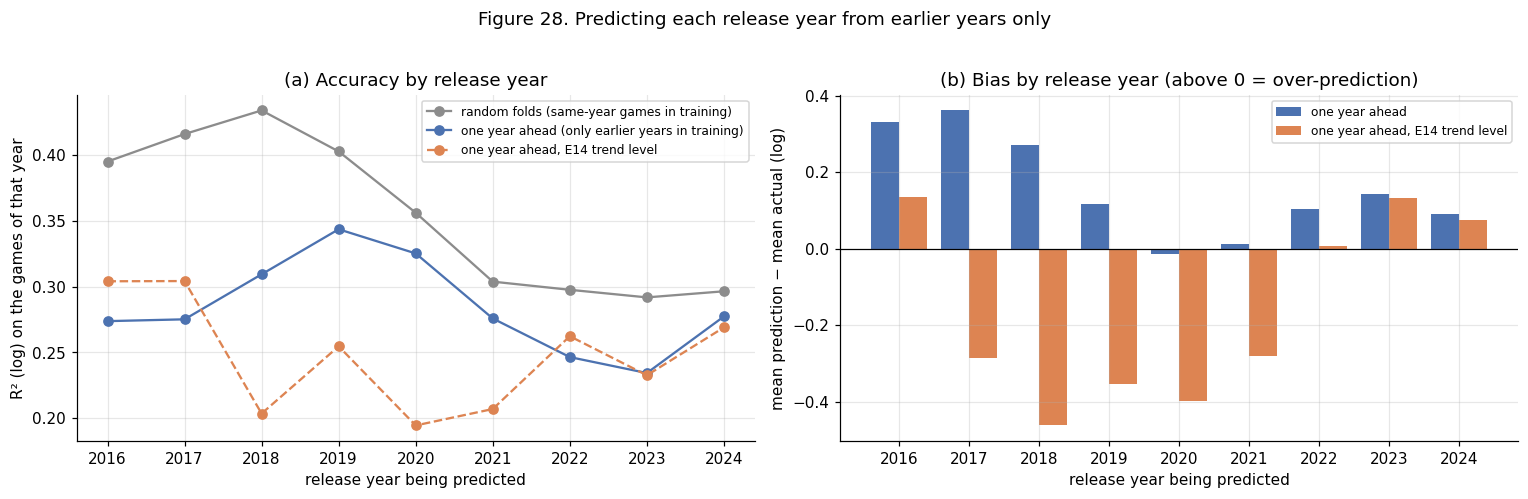

,Games,Fitted on earlier games,Random-fold R² (log),One-year-ahead R² (log),One-year-ahead bias (log),E14 trend level: R² (log),E14 trend level: bias (log)
Release year,,,,,,,
2016,"3,231","4,687",0.395,0.274,+0.331,0.304,+0.135
2017,"4,608","7,918",0.416,0.275,+0.361,0.304,-0.286
2018,"5,755","12,526",0.434,0.309,+0.272,0.204,-0.463
2019,"5,743","18,281",0.403,0.343,+0.117,0.255,-0.355
2020,"6,875","24,024",0.356,0.325,-0.013,0.195,-0.398
2021,"7,551","30,899",0.304,0.276,+0.012,0.207,-0.280
2022,"8,062","38,450",0.298,0.246,+0.103,0.262,+0.007
2023,"9,251","46,512",0.292,0.234,+0.142,0.233,+0.132
2024,"5,618","55,763",0.296,0.277,+0.091,0.269,+0.076


In [6]:
y_all, year_all = train["log_owners"].to_numpy(), train["release_year"].to_numpy()
rows, bias_rows = [], []
for year in range(2016, 2025):
    earlier, target = train[train["release_year"] < year], train[train["release_year"] == year]
    ahead = evaluate(target, forecast(ADOPTED, earlier, target))
    trend = evaluate(target, forecast(ADOPTED, earlier, target, relative=True, level="trend"))
    in_year = year_all == year
    rows.append({"Release year": year, "Games": len(target), "Fitted on earlier games": len(earlier),
                 "Random-fold R² (log)": r2_score(y_all[in_year], reference_oof[in_year]),
                 "One-year-ahead R² (log)": ahead["R² (log)"], "One-year-ahead bias (log)": ahead["Bias (log)"],
                 "E14 trend level: R² (log)": trend["R² (log)"], "E14 trend level: bias (log)": trend["Bias (log)"]})
table40 = pd.DataFrame(rows).set_index("Release year")
table40.to_csv(os.path.join(TAB_DIR, "table40_one_year_ahead.csv"))
recent = table40.loc[2022:2024]
print(f"Mean over 2022–2024: random-fold R² {recent['Random-fold R² (log)'].mean():.3f} | "
      f"one-year-ahead R² {recent['One-year-ahead R² (log)'].mean():.3f} | "
      f"E14 trend level R² {recent['E14 trend level: R² (log)'].mean():.3f}")
print(f"Mean over 2016–2024: one-year-ahead R² {table40['One-year-ahead R² (log)'].mean():.3f} | "
      f"E14 trend level R² {table40['E14 trend level: R² (log)'].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
x = table40.index
axes[0].plot(x, table40["Random-fold R² (log)"], "o-", color=GREY, label="random folds (same-year games in training)")
axes[0].plot(x, table40["One-year-ahead R² (log)"], "o-", color=BLUE, label="one year ahead (only earlier years in training)")
axes[0].plot(x, table40["E14 trend level: R² (log)"], "o--", color=ORANGE, label="one year ahead, E14 trend level")
axes[0].set_ylabel("R² (log) on the games of that year")
axes[0].set_title("(a) Accuracy by release year")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].bar(x - 0.2, table40["One-year-ahead bias (log)"], 0.4, color=BLUE, label="one year ahead")
axes[1].bar(x + 0.2, table40["E14 trend level: bias (log)"], 0.4, color=ORANGE, label="one year ahead, E14 trend level")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("mean prediction − mean actual (log)")
axes[1].set_title("(b) Bias by release year (above 0 = over-prediction)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(x)
    ax.set_xlabel("release year being predicted")
fig.suptitle("Figure 28. Predicting each release year from earlier years only", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig28_one_year_ahead.png"), dpi=150, bbox_inches="tight")
plt.show()
table40.style.format({"Games": "{:,}", "Fitted on earlier games": "{:,}", "Random-fold R² (log)": "{:.3f}",
                      "One-year-ahead R² (log)": "{:.3f}", "One-year-ahead bias (log)": "{:+.3f}",
                      "E14 trend level: R² (log)": "{:.3f}", "E14 trend level: bias (log)": "{:+.3f}"}).set_caption(
    "Table 40. One-year-ahead evaluation: each release year predicted by a model fitted on all earlier training-set games")

**Interpretation.**
- **One year ahead, the model loses little.** For 2022, 2023 and 2024 releases the one-year-ahead R² (log) is
  0.246, 0.234 and 0.277 (mean 0.253), against 0.298, 0.292 and 0.296 with random folds (mean 0.295). Not
  having same-year games in training costs about 0.04. The 0.165 of Section 13.3 is lower because that model
  predicts up to two and a half years ahead without retraining.
- **Recent years are harder whichever way they are scored.** Even with random folds, R² falls from 0.434 for
  2018 releases to about 0.30 for 2021–2024 releases, in line with the narrowing spread of Section 13.1.
- **One-year-ahead predictions are usually too high.** The bias is +0.10, +0.14 and +0.09 for 2022–2024. It was
  larger for 2016–2018 (+0.27 to +0.36), when the year level was falling fast, and close to zero for 2020 and
  2021.
- **The trend level (E14) is not reliable.** It helps for 2016, 2017 and 2022, but for 2018–2021 it lowers R²
  to 0.19–0.25, against 0.28–0.34 without it, and turns the bias to between −0.28 and −0.46. The year level
  stopped falling steeply after 2018, and a straight line through earlier years overshoots. Over all nine
  years its mean R² is 0.248 against 0.285. Its gain in Section 13.3 does not hold, so it is not adopted.

---
## 13.5 Findings and decision

**Findings.**
1. **Most of the gap between 0.460 and 0.165 is not a forecasting failure.** The largest part (−0.162) appears
   as soon as only 2022–2024 games are scored, even with random folds: recent games are harder to tell apart,
   and the overall score is helped by differences between release years.
2. **The release-year level is the smallest part (−0.051).** Notebook 7 named it as the main cause; that is
   corrected here.
3. **The planned fix does not work.** A year-relative target leaves the chronological score unchanged (0.167
   against 0.164), because Gradient Boosting already learns the level of each year from release year.
4. **Release year has to stay.** Removing it lowers both the random-fold score (0.460 → 0.357) and the
   chronological score (0.164 → −0.011).
5. **None of the four changes is adopted.** Training on recent years only stays within seed noise. A trend for
   the year level helps on one split and fails in the year-by-year check.
6. **The accuracy that can be claimed for an unreleased game is about R² (log) 0.25**, one year ahead with
   yearly retraining, with predictions roughly 10–15% too high. The random-fold 0.460 describes how well
   the variables explain owners across all years, not how well a future game can be forecast.

**Decision.**
- **Reference model:** unchanged. Gradient Boosting on log1p(owners) with the 49 variables of Notebook 7.
- **Reporting:** three numbers from now on: random-fold R², one-year-ahead R² and one-year-ahead bias.
- **Use:** a forecast should come from a model retrained on all games released so far.

**Next steps.**
1. Change the question for recent games. Most of them share the lowest owner range, so predicting whether a
   game rises above it (a classification task) may suit this target better than regression.
2. Find past-sales information dated before each release (Notebook 7, E10), the only variable group so far
   that raised the chronological score clearly.
3. Tune Gradient Boosting with nested cross-validation, scored one year ahead.